# RouteRanker – Milestone 2: Exploratory Data Analysis & Data Processing

**Project:** AI-Powered Public Transit Route Optimization  
**City:** Chennai, Tamil Nadu  
**Operator:** Chennai Metropolitan Transport Corporation (MTC)  
**Milestone period:** Weeks 3–4

## Objective
Explore Chennai MTC's GTFS network and scheduled service patterns, identify routes with similar stop coverage, create route-level analytical features, and prepare scaled datasets for later machine-learning experiments.

## Important data limitation
GTFS contains scheduled routes, trips, stops and stop times. It does **not** contain passenger boardings or passenger occupancy by route and time. Therefore:
- Hourly curves in this notebook show **scheduled trip starts**, not hourly ridership.
- Geographic heatmaps show **GTFS stop/network concentration**, not passenger density.
- A route with fewer scheduled trips is only a low-service-supply candidate for review; it cannot be called underutilized without passenger-demand data.
- Classification labels such as balanced/overcrowded are not fabricated. A real route-level target label is required before supervised classification can be trained.

**Input:** Chennai MTC GTFS feed from https://github.com/ungalsoththu/ChennaiGTFS

## 1. Import required libraries
Import data handling, visualization and preprocessing libraries.

In [1]:
import urllib.request
import zipfile
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Download and extract Chennai MTC GTFS data
The notebook downloads the same GTFS feed used in Milestone 1. If the ZIP is already present in the Colab runtime, it is reused.

In [2]:
PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw"
GTFS_DIR = RAW_DIR / "mtc_gtfs"
ZIP_PATH = RAW_DIR / "mtc-gtfs.zip"
OUTPUT_DIR = PROJECT_DIR / "data" / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
GTFS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_URL = "https://github.com/ungalsoththu/ChennaiGTFS/raw/refs/heads/main/data/mtc-gtfs.zip"

if not ZIP_PATH.exists():
    print("Downloading Chennai MTC GTFS feed...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(GTFS_DIR)

def find_gtfs_file(filename):
    matches = list(GTFS_DIR.rglob(filename))
    return matches[0] if matches else None

gtfs_paths = {
    name: find_gtfs_file(name)
    for name in ["routes.txt", "trips.txt", "stops.txt", "stop_times.txt"]
}
for name, path in gtfs_paths.items():
    print(f"{name}: {path if path else 'NOT FOUND'}")

missing_files = [name for name, path in gtfs_paths.items() if path is None]
if missing_files:
    raise FileNotFoundError("Missing GTFS files: " + ", ".join(missing_files))

routes.txt: /content/data/raw/mtc_gtfs/routes.txt
trips.txt: /content/data/raw/mtc_gtfs/trips.txt
stops.txt: /content/data/raw/mtc_gtfs/stops.txt
stop_times.txt: /content/data/raw/mtc_gtfs/stop_times.txt


## 3. Load the main GTFS tables
Identifiers are loaded as strings to preserve their original values.

In [3]:
routes = pd.read_csv(gtfs_paths["routes.txt"], dtype=str)
trips = pd.read_csv(gtfs_paths["trips.txt"], dtype=str)
stops = pd.read_csv(gtfs_paths["stops.txt"], dtype=str)
stop_times = pd.read_csv(gtfs_paths["stop_times.txt"], dtype=str)

print("Routes:", routes.shape)
print("Trips:", trips.shape)
print("Stops:", stops.shape)
print("Stop times:", stop_times.shape)

Routes: (4611, 5)
Trips: (47047, 4)
Stops: (5580, 4)
Stop times: (1360443, 5)


## 4. Validate required columns and prepare working copies
This step checks the identifiers needed for route, trip, stop and schedule analysis.

In [4]:
required = {
    "routes": {"route_id"},
    "trips": {"trip_id", "route_id"},
    "stops": {"stop_id", "stop_lat", "stop_lon"},
    "stop_times": {"trip_id", "stop_id", "stop_sequence", "departure_time"}
}
frames = {"routes": routes, "trips": trips, "stops": stops, "stop_times": stop_times}

for name, cols in required.items():
    absent = cols - set(frames[name].columns)
    if absent:
        raise ValueError(f"{name} is missing required columns: {sorted(absent)}")

routes = routes.drop_duplicates().copy()
trips = trips.drop_duplicates().copy()
stops = stops.drop_duplicates().copy()
stop_times = stop_times.drop_duplicates().copy()

print("Required columns checked; exact duplicate rows removed from working copies.")
print("Original source files remain unchanged.")

Required columns checked; exact duplicate rows removed from working copies.
Original source files remain unchanged.


## 5. Create a route-level analytical feature table
Features describe scheduled service and network structure, not passenger demand.

In [5]:
trip_counts = trips.groupby("route_id")["trip_id"].nunique().rename("scheduled_trip_records")
trip_stop_counts = stop_times.groupby("trip_id").size().rename("stops_in_trip")

trip_route = trips[["trip_id", "route_id"]].merge(
    trip_stop_counts, on="trip_id", how="left"
)
route_stop_stats = trip_route.groupby("route_id").agg(
    average_stops_per_trip=("stops_in_trip", "mean"),
    trips_with_stop_time_data=("trip_id", "nunique")
)

route_unique_stops = (
    trips[["trip_id", "route_id"]]
    .merge(stop_times[["trip_id", "stop_id"]], on="trip_id", how="inner")
    .groupby("route_id")["stop_id"].nunique()
    .rename("unique_stops_per_route")
)

route_features = (
    routes[["route_id"]]
    .drop_duplicates()
    .set_index("route_id")
    .join(trip_counts)
    .join(route_stop_stats)
    .join(route_unique_stops)
    .reset_index()
)

route_features["scheduled_trip_records"] = route_features["scheduled_trip_records"].fillna(0)
display(route_features.head(10))
print("Route feature table:", route_features.shape)

,route_id,scheduled_trip_records,average_stops_per_trip,trips_with_stop_time_data,unique_stops_per_route
0,18751,106.0,29.0,106.0,29.0
1,18750,1.0,29.0,1.0,29.0
2,23728,40.0,22.0,40.0,22.0
3,18753,1.0,25.0,1.0,25.0
4,20494,16.0,4.0,16.0,4.0
5,23729,30.0,25.0,30.0,25.0
6,18755,2.0,32.0,2.0,32.0
7,18756,5.0,42.0,5.0,42.0
8,18758,2.0,40.0,2.0,40.0
9,18761,0.0,NaN,NaN,NaN


Route feature table: (4611, 5)


## 6. Explore route service patterns
Rank routes by the number of trip records in the published GTFS schedule.

,route_id,scheduled_trip_records,average_stops_per_trip,trips_with_stop_time_data,unique_stops_per_route
2408,20163,210.0,33.0,210.0,33.0
2420,20167,208.0,37.0,208.0,37.0
1259,24072,202.0,36.0,202.0,36.0
1267,24073,202.0,35.0,202.0,35.0
375,20578,197.0,25.0,197.0,25.0
3955,22698,186.0,36.0,186.0,36.0
3956,22699,186.0,34.0,186.0,34.0
1219,24065,185.0,26.0,185.0,26.0
1232,24066,185.0,23.0,185.0,23.0
4010,22800,181.0,27.0,181.0,27.0


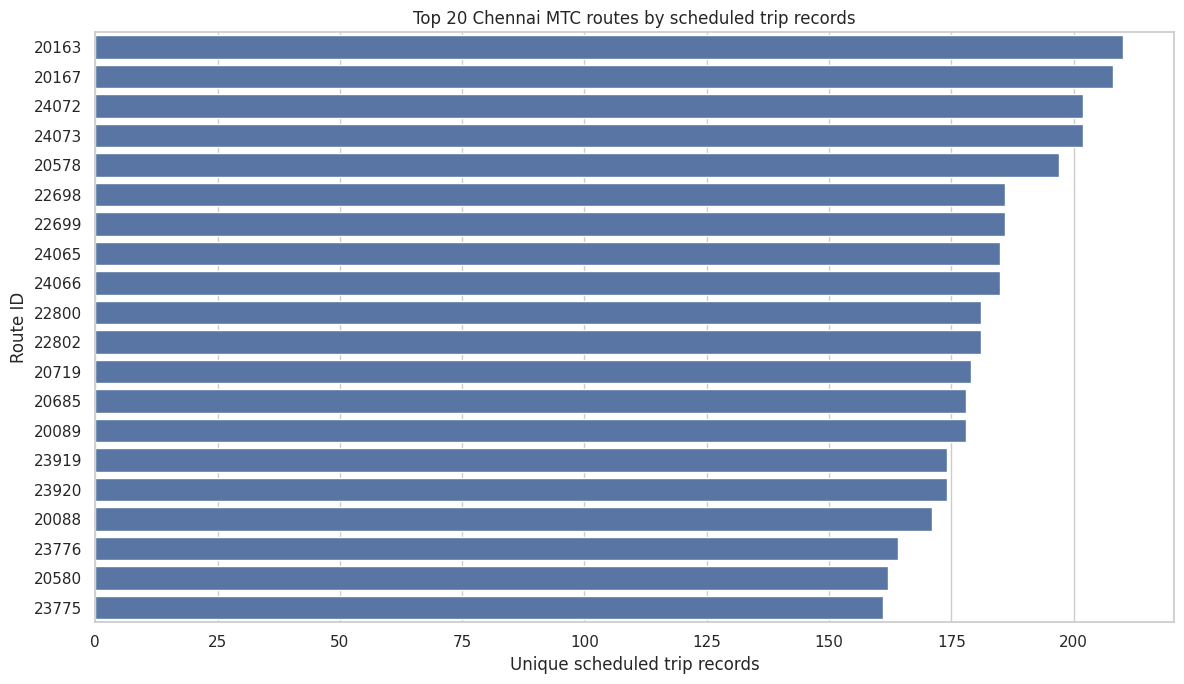

In [8]:
top_routes = route_features.nlargest(20, "scheduled_trip_records").copy()
display(top_routes)

plt.figure(figsize=(12, 7))
sns.barplot(data=top_routes, x="scheduled_trip_records", y="route_id")
plt.title("Top 20 Chennai MTC routes by scheduled trip records")
plt.xlabel("Unique scheduled trip records")
plt.ylabel("Route ID")
plt.tight_layout()
plt.show()

## 7. Analyze scheduled trip starts by hour
The first stop-time departure for each trip is used. GTFS times beyond 24:00 are retained as service-day hours.

,service_hour,scheduled_trip_starts
0,0,104
1,1,105
2,2,103
3,3,193
4,4,840
5,5,2101
6,6,2941
7,7,2718
8,8,2752
9,9,2588


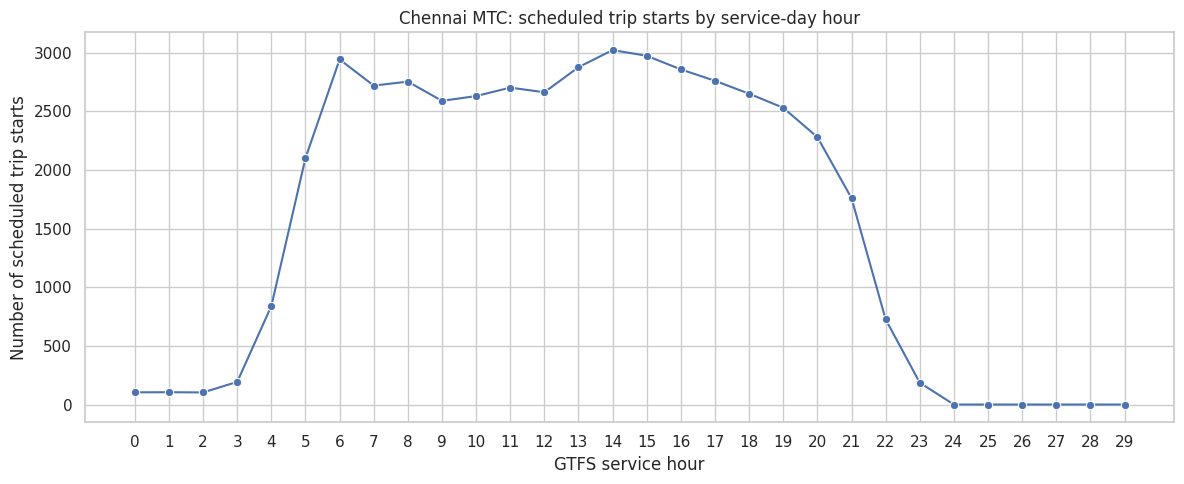

In [9]:
first_departures = (
    stop_times.sort_values(["trip_id", "stop_sequence"])
    .drop_duplicates("trip_id", keep="first")
    [["trip_id", "departure_time"]]
    .merge(trips[["trip_id", "route_id"]], on="trip_id", how="left")
)

def gtfs_hour(value):
    try:
        return int(str(value).split(":")[0])
    except (ValueError, TypeError, IndexError):
        return np.nan

first_departures["service_hour"] = first_departures["departure_time"].map(gtfs_hour)
hourly_schedule = (
    first_departures.dropna(subset=["service_hour"])
    .groupby("service_hour")["trip_id"].nunique()
    .reindex(range(0, 30), fill_value=0)
    .rename("scheduled_trip_starts")
    .reset_index()
)

display(hourly_schedule)
plt.figure(figsize=(12, 5))
sns.lineplot(data=hourly_schedule, x="service_hour", y="scheduled_trip_starts", marker="o")
plt.title("Chennai MTC: scheduled trip starts by service-day hour")
plt.xlabel("GTFS service hour")
plt.ylabel("Number of scheduled trip starts")
plt.xticks(range(0, 30))
plt.tight_layout()
plt.show()

## 8. Compare hourly schedules across selected routes
This chart compares scheduled departures for the routes with the most trip records. It is not a ridership curve.

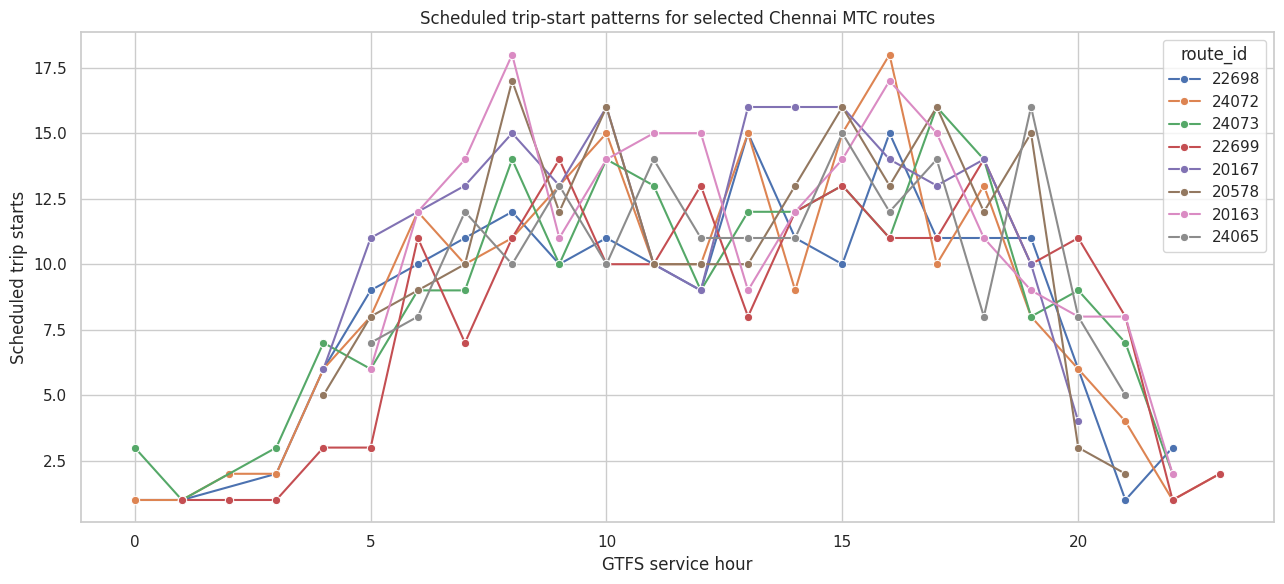

In [10]:
selected_route_ids = top_routes["route_id"].head(8).tolist()
route_hourly = (
    first_departures[first_departures["route_id"].isin(selected_route_ids)]
    .dropna(subset=["service_hour"])
    .groupby(["service_hour", "route_id"])["trip_id"].nunique()
    .reset_index(name="scheduled_trip_starts")
)

plt.figure(figsize=(13, 6))
if not route_hourly.empty:
    sns.lineplot(data=route_hourly, x="service_hour", y="scheduled_trip_starts",
                 hue="route_id", marker="o")
plt.title("Scheduled trip-start patterns for selected Chennai MTC routes")
plt.xlabel("GTFS service hour")
plt.ylabel("Scheduled trip starts")
plt.tight_layout()
plt.show()

## 9. Create a GTFS stop/network density heatmap
Stop coordinates are plotted and weighted by the number of distinct routes serving each stop. This represents network concentration only, not passenger density.

,stop_id,stop_lat,stop_lon,route_count
3335,5822,13.06880,80.20520,600.0
2738,6693,12.92772,80.11864,367.0
922,11159,13.07826,80.28144,316.0
921,11158,13.10212,80.29424,271.0
504,5785,13.01364,80.22658,246.0
756,9991,12.87351,80.07858,240.0
505,5823,13.03467,80.23001,222.0
1815,5578,13.18551,80.19125,222.0
5393,10430,13.11921,80.09954,209.0
672,1048,13.01186,80.22195,206.0


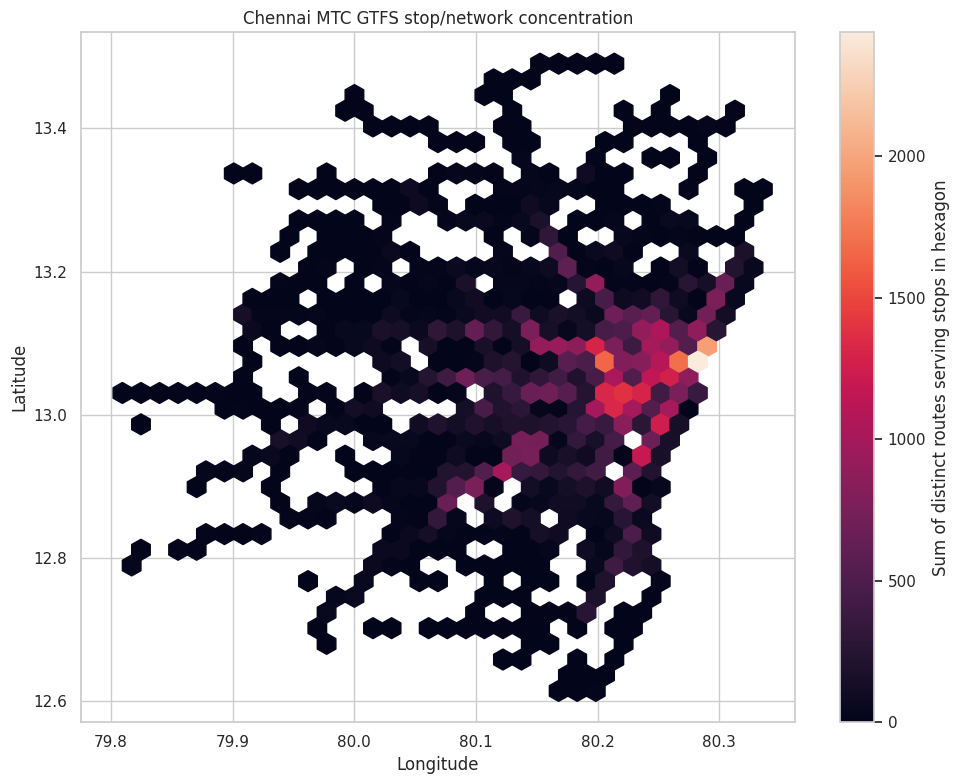

In [11]:
trip_stop_route = (
    trips[["trip_id", "route_id"]]
    .merge(stop_times[["trip_id", "stop_id"]], on="trip_id", how="inner")
    [["route_id", "stop_id"]].drop_duplicates()
)
stop_route_counts = trip_stop_route.groupby("stop_id")["route_id"].nunique().rename("route_count")

stop_geo = stops[["stop_id", "stop_lat", "stop_lon"]].copy()
stop_geo["stop_lat"] = pd.to_numeric(stop_geo["stop_lat"], errors="coerce")
stop_geo["stop_lon"] = pd.to_numeric(stop_geo["stop_lon"], errors="coerce")
stop_geo = stop_geo.dropna(subset=["stop_lat", "stop_lon"]).merge(
    stop_route_counts, on="stop_id", how="left"
)
stop_geo["route_count"] = stop_geo["route_count"].fillna(0)

display(stop_geo.nlargest(10, "route_count"))

plt.figure(figsize=(10, 8))
hb = plt.hexbin(stop_geo["stop_lon"], stop_geo["stop_lat"],
                C=stop_geo["route_count"], reduce_C_function=np.sum,
                gridsize=35, mincnt=1)
plt.colorbar(hb, label="Sum of distinct routes serving stops in hexagon")
plt.title("Chennai MTC GTFS stop/network concentration")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

## 10. Identify route overlap using shared stops
For each route pair, calculate the Jaccard similarity of their stop sets. A higher score means a larger share of stops is common. Shared stops alone do not prove that two routes follow the same road or should be merged.

In [12]:
route_stop_sets = (
    trip_stop_route.groupby("route_id")["stop_id"]
    .apply(lambda x: set(x))
    .to_dict()
)
route_ids = sorted(route_stop_sets)
overlap_rows = []

for i, route_a in enumerate(route_ids):
    stops_a = route_stop_sets[route_a]
    for route_b in route_ids[i + 1:]:
        stops_b = route_stop_sets[route_b]
        union = stops_a | stops_b
        if union:
            shared = stops_a & stops_b
            score = len(shared) / len(union)
            if len(shared) >= 3:
                overlap_rows.append({
                    "route_a": route_a,
                    "route_b": route_b,
                    "shared_stops": len(shared),
                    "jaccard_similarity": score
                })

overlap_pairs = pd.DataFrame(overlap_rows)
if not overlap_pairs.empty:
    overlap_pairs = overlap_pairs.sort_values(
        ["jaccard_similarity", "shared_stops"], ascending=False
    )
display(overlap_pairs.head(25))
print("Route pairs with at least 3 shared stops:", len(overlap_pairs))

,route_a,route_b,shared_stops,jaccard_similarity
209692,21141,21143,66,1.0
117859,16406,16423,65,1.0
276973,23147,23196,59,1.0
148264,18510,20566,56,1.0
206498,21067,21357,55,1.0
106702,15222,17652,51,1.0
106728,15222,19462,51,1.0
106729,15222,19463,51,1.0
132057,17652,19462,51,1.0
132058,17652,19463,51,1.0


Route pairs with at least 3 shared stops: 288766


# 11. Visualize the strongest route overlaps
The heatmap shows pairwise Jaccard similarity for a manageable shortlist of routes with the highest overlap scores.

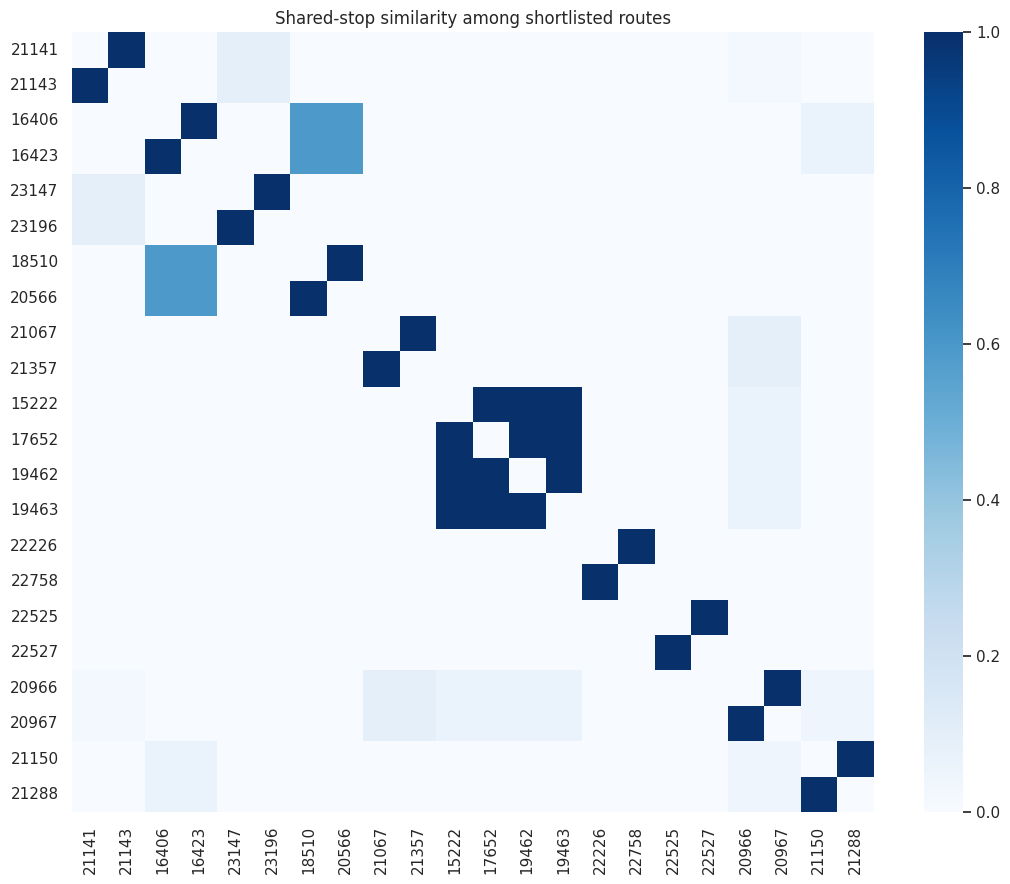

In [13]:
if not overlap_pairs.empty:
    top_overlap_routes = pd.unique(
        overlap_pairs.head(15)[["route_a", "route_b"]].values.ravel()
    ).tolist()
    overlap_matrix = pd.DataFrame(0.0, index=top_overlap_routes, columns=top_overlap_routes)
    for row in overlap_pairs.itertuples(index=False):
        if row.route_a in overlap_matrix.index and row.route_b in overlap_matrix.columns:
            overlap_matrix.loc[row.route_a, row.route_b] = row.jaccard_similarity
            overlap_matrix.loc[row.route_b, row.route_a] = row.jaccard_similarity

    plt.figure(figsize=(11, 9))
    sns.heatmap(overlap_matrix, cmap="Blues", vmin=0, vmax=1)
    plt.title("Shared-stop similarity among shortlisted routes")
    plt.tight_layout()
    plt.show()
else:
    print("No route pairs met the minimum shared-stop threshold.")

## 12. Flag low scheduled-service routes for review
This section identifies routes with relatively few scheduled trip records. These are **low scheduled-service candidates**, not confirmed underutilized routes. Passenger counts are needed to assess demand.

In [14]:
service_cutoff = route_features["scheduled_trip_records"].quantile(0.25)
low_service_candidates = route_features[
    route_features["scheduled_trip_records"] <= service_cutoff
].sort_values("scheduled_trip_records")

display(low_service_candidates.head(25))
print(f"Lower-quartile scheduled-trip threshold: {service_cutoff:.2f}")
print("Interpretation: review these routes with operational and passenger-demand data; do not label them underutilized from GTFS alone.")

,route_id,scheduled_trip_records,average_stops_per_trip,trips_with_stop_time_data,unique_stops_per_route
4526,23542,0.0,NaN,NaN,NaN
4527,23543,0.0,NaN,NaN,NaN
4529,23545,0.0,NaN,NaN,NaN
4531,23547,0.0,NaN,NaN,NaN
4532,23548,0.0,NaN,NaN,NaN
4534,23551,0.0,NaN,NaN,NaN
4539,23559,0.0,NaN,NaN,NaN
4552,23572,0.0,NaN,NaN,NaN
1921,13163,0.0,NaN,NaN,NaN
1922,13164,0.0,NaN,NaN,NaN


Lower-quartile scheduled-trip threshold: 1.00
Interpretation: review these routes with operational and passenger-demand data; do not label them underutilized from GTFS alone.


## 13. Review missing values and feature distributions
Summarize missing values and inspect the distributions before preprocessing.

,missing_values
route_id,0
scheduled_trip_records,0
average_stops_per_trip,677
trips_with_stop_time_data,677
unique_stops_per_route,677


,count,mean,std,min,25%,50%,75%,max
scheduled_trip_records,4611.0,10.203210,22.235305,0.0,1.0,3.0,8.0,210.0
average_stops_per_trip,3934.0,24.405948,13.683862,2.0,14.0,23.0,33.0,80.0
trips_with_stop_time_data,3934.0,11.959075,23.632798,1.0,2.0,4.0,10.0,210.0
unique_stops_per_route,3934.0,24.405948,13.683862,2.0,14.0,23.0,33.0,80.0


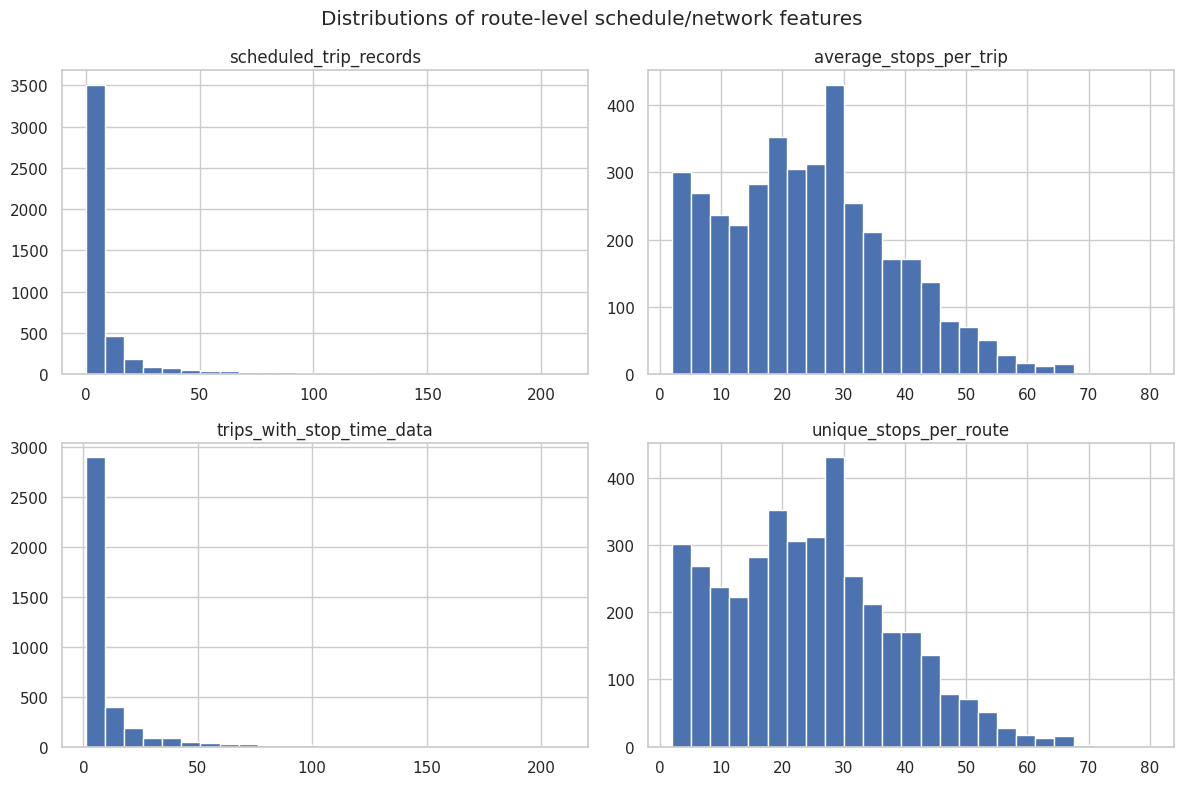

In [15]:
missing_summary = route_features.isna().sum().rename("missing_values").to_frame()
display(missing_summary)

numeric_features = [
    "scheduled_trip_records",
    "average_stops_per_trip",
    "trips_with_stop_time_data",
    "unique_stops_per_route"
]
display(route_features[numeric_features].describe().T)

route_features[numeric_features].hist(figsize=(12, 8), bins=25)
plt.suptitle("Distributions of route-level schedule/network features")
plt.tight_layout()
plt.show()

## 14. Prepare the numeric feature matrix
The route ID is retained as an identifier, not treated as a numeric measurement. Numeric feature columns are imputed where necessary and standardized.

In [16]:
feature_columns = [
    "scheduled_trip_records",
    "average_stops_per_trip",
    "trips_with_stop_time_data",
    "unique_stops_per_route"
]
X_numeric = route_features[feature_columns].replace([np.inf, -np.inf], np.nan)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_scaled_array = numeric_pipeline.fit_transform(X_numeric)
X_scaled = pd.DataFrame(X_scaled_array, columns=feature_columns)
X_scaled.insert(0, "route_id", route_features["route_id"].values)

display(X_scaled.head(10))
print("Scaled feature matrix shape:", X_scaled.shape)

,route_id,scheduled_trip_records,average_stops_per_trip,trips_with_stop_time_data,unique_stops_per_route
0,18751,4.308786,0.379555,4.326269,0.379555
1,18750,-0.413946,0.379555,-0.444875,0.379555
2,23728,1.340212,-0.173908,1.327264,-0.173908
3,18753,-0.413946,0.063291,-0.444875,0.063291
4,20494,0.260730,-1.597098,0.236717,-1.597098
5,23729,0.890428,0.063291,0.872869,0.063291
6,18755,-0.368967,0.616754,-0.399436,0.616754
7,18756,-0.234032,1.407415,-0.263117,1.407415
8,18758,-0.368967,1.249283,-0.399436,1.249283
9,18761,-0.458924,-0.094842,-0.308557,-0.094842


Scaled feature matrix shape: (4611, 5)


## 15. Encode route identifiers as categorical metadata
Route IDs are categorical identifiers. One-hot encoding is demonstrated for downstream pipelines, but the encoded route identity should not automatically be treated as evidence of route performance.

In [17]:
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

route_id_encoded = encoder.fit_transform(route_features[["route_id"]])
encoded_route_columns = encoder.get_feature_names_out(["route_id"])
route_id_encoded_df = pd.DataFrame(route_id_encoded, columns=encoded_route_columns)

print("Number of route categories:", len(encoded_route_columns))
display(route_id_encoded_df.head())

Number of route categories: 4611


,route_id_10003,route_id_10083,route_id_10084,route_id_10090,route_id_10114,route_id_10138,route_id_10145,route_id_10147,route_id_10152,route_id_10154,route_id_10160,route_id_10176,route_id_10202,route_id_10213,route_id_10214,route_id_10219,route_id_10224,route_id_10225,route_id_10241,route_id_10248,route_id_10251,route_id_10272,route_id_10303,route_id_10304,route_id_10305,route_id_10349,route_id_10350,route_id_10355,route_id_10356,route_id_10357,route_id_10368,route_id_10392,route_id_10394,route_id_10400,route_id_10415,route_id_10416,route_id_10419,route_id_10426,route_id_10431,route_id_10443,route_id_10457,route_id_10458,route_id_10467,route_id_10482,route_id_10489,route_id_10492,route_id_10510,route_id_10514,route_id_10515,route_id_10517,...,route_id_8458,route_id_8472,route_id_8486,route_id_8489,route_id_8580,route_id_8631,route_id_8640,route_id_8672,route_id_8728,route_id_8868,route_id_8917,route_id_9021,route_id_9022,route_id_9023,route_id_9025,route_id_9052,route_id_9064,route_id_9074,route_id_9293,route_id_9295,route_id_9312,route_id_9320,route_id_9377,route_id_9378,route_id_9379,route_id_938,route_id_9455,route_id_9456,route_id_9466,route_id_9469,route_id_9560,route_id_9596,route_id_9632,route_id_9634,route_id_9666,route_id_9750,route_id_9753,route_id_9756,route_id_9771,route_id_9774,route_id_9782,route_id_9783,route_id_9862,route_id_9929,route_id_9953,route_id_9955,route_id_9981,route_id_9982,route_id_9986,route_id_9992
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 16. Prepare the clustering dataset
The clustering dataset uses scaled operational/network features. It excludes route IDs so clusters are based on the numeric schedule/network profile.

In [18]:
clustering_features = X_scaled[feature_columns].copy()
display(clustering_features.head())
print("Clustering dataset ready:", clustering_features.shape)

,scheduled_trip_records,average_stops_per_trip,trips_with_stop_time_data,unique_stops_per_route
0,4.308786,0.379555,4.326269,0.379555
1,-0.413946,0.379555,-0.444875,0.379555
2,1.340212,-0.173908,1.327264,-0.173908
3,-0.413946,0.063291,-0.444875,0.063291
4,0.260730,-1.597098,0.236717,-1.597098


Clustering dataset ready: (4611, 4)


## 17. Create training and validation feature splits
An 80/20 split is prepared for later experiments. Since this milestone has no verified route-level outcome labels, this is a feature split only; it is not a trained or evaluated supervised classifier.

In [19]:
X_train, X_validation = train_test_split(
    clustering_features,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training feature rows:", len(X_train))
print("Validation feature rows:", len(X_validation))
print("Training feature shape:", X_train.shape)
print("Validation feature shape:", X_validation.shape)

classification_ready = False
print("Supervised classification ready:", classification_ready)
print("Reason: no verified route-level target label (for example, measured occupancy category) is present in this GTFS feed.")

Training feature rows: 3688
Validation feature rows: 923
Training feature shape: (3688, 4)
Validation feature shape: (923, 4)
Supervised classification ready: False
Reason: no verified route-level target label (for example, measured occupancy category) is present in this GTFS feed.
